In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import *
from src.models import *
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models, compare_models_staggered, dm_table

/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


### ==== Validation =====

In [2]:
spot = load_brent_spot(start="1987-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()


val_args = dict(horizon=30, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")


val_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **val_args),
    "Direct Lag_1 Lag_30": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=30, lookback=3000, **val_args),
    "Direct Lag_5 Lag_30": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=30, lookback=3000, **val_args)
}

compare_models_staggered(val_results, horizon=30)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,4.524885,5.620237,6.062684,0.002096,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,446
Historical Mean,4.504488,5.607664,6.015694,0.591195,0.000000,0.000000,0.000000,0.591195,1.000000,0.743083,0.123476,0.291321,0.423847,-0.263059,1.000000,0.000000,0.000000,446
AR,4.503305,5.606345,6.014001,0.582809,0.000000,0.000000,0.000000,0.587738,0.985816,0.736424,0.104216,0.287376,0.362647,-0.263059,0.982063,0.000000,0.301345,446
Direct Forecast,4.423843,5.502342,5.914038,0.605870,0.535354,0.273196,0.361775,0.624339,0.836879,0.715152,0.193575,0.195569,0.989803,-0.139683,0.669656,0.147982,6.365919,446
Direct Lag_1 Lag_30,4.423277,5.506567,5.918018,0.566038,0.456522,0.324742,0.379518,0.610619,0.734043,0.666667,0.104908,0.139874,0.750019,-0.111747,0.463229,0.107623,7.646637,446
Direct Lag_5 Lag_30,4.579650,5.683637,6.135668,0.488470,0.366120,0.345361,0.355438,0.564626,0.588652,0.576389,-0.032458,0.103383,-0.313959,-0.196364,0.317040,0.213004,7.571300,446


#### Mean Revert

In [3]:
# PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
# INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

df_mr = load_dataset()
df_mr = df_mr[["brent_spot", "wti"]]
df_mr = df_mr.rename(columns={"wti": "wti_spot"})
df_mr["log_return"] = np.log(df_mr["brent_spot"]).diff()
df_mr = df_mr.dropna()

df_mr.tail()

,brent_spot,wti_spot,log_return
DATE,,,
2026-10-21,117.37,103.95,0.018488
2026-10-22,125.39,104.27,0.066098
2026-10-23,128.30,109.72,0.022942
2026-10-26,128.12,105.25,-0.001404
2026-10-27,123.10,103.37,-0.039970


In [4]:
val_forecast = walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
472,2025-11-11,2025-12-23,63.86,64.115036,63.70
473,2025-11-12,2025-12-24,61.88,62.312017,63.70
474,2025-11-13,2025-12-29,62.14,62.565866,63.10
475,2025-11-14,2025-12-30,63.45,63.940461,62.30
476,2025-11-17,2025-12-31,63.16,63.698597,61.35


In [5]:
val_results["Mean Revert"] = val_forecast

compare_models_staggered(val_results, horizon=30)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,4.524885,5.620237,6.062684,0.002096,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,446
Historical Mean,4.504488,5.607664,6.015694,0.591195,0.000000,0.000000,0.000000,0.591195,1.000000,0.743083,0.123476,0.291321,0.423847,-0.263059,1.000000,0.000000,0.000000,446
AR,4.503305,5.606345,6.014001,0.582809,0.000000,0.000000,0.000000,0.587738,0.985816,0.736424,0.104216,0.287376,0.362647,-0.263059,0.982063,0.000000,0.301345,446
Direct Forecast,4.423843,5.502342,5.914038,0.605870,0.535354,0.273196,0.361775,0.624339,0.836879,0.715152,0.193575,0.195569,0.989803,-0.139683,0.669656,0.147982,6.365919,446
Direct Lag_1 Lag_30,4.423277,5.506567,5.918018,0.566038,0.456522,0.324742,0.379518,0.610619,0.734043,0.666667,0.104908,0.139874,0.750019,-0.111747,0.463229,0.107623,7.646637,446
Direct Lag_5 Lag_30,4.579650,5.683637,6.135668,0.488470,0.366120,0.345361,0.355438,0.564626,0.588652,0.576389,-0.032458,0.103383,-0.313959,-0.196364,0.317040,0.213004,7.571300,446
Mean Revert,4.639714,5.725567,6.214233,0.440252,0.385580,0.634021,0.479532,0.550633,0.308511,0.395455,-0.021833,0.214624,-0.101725,-0.274348,0.665919,0.699552,7.533632,446


#### XGBoost

In [6]:
val_forecast = walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
472,2025-11-11,2025-12-23,63.86,63.794958,63.70
473,2025-11-12,2025-12-24,61.88,61.401439,63.70
474,2025-11-13,2025-12-29,62.14,61.538509,63.10
475,2025-11-14,2025-12-30,63.45,62.636506,62.30
476,2025-11-17,2025-12-31,63.16,62.210906,61.35


In [7]:
val_results["XGBoost"] = val_forecast

compare_models_staggered(val_results, horizon=30)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,4.524885,5.620237,6.062684,0.002096,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,446
Historical Mean,4.504488,5.607664,6.015694,0.591195,0.000000,0.000000,0.000000,0.591195,1.000000,0.743083,0.123476,0.291321,0.423847,-0.263059,1.000000,0.000000,0.000000,446
AR,4.503305,5.606345,6.014001,0.582809,0.000000,0.000000,0.000000,0.587738,0.985816,0.736424,0.104216,0.287376,0.362647,-0.263059,0.982063,0.000000,0.301345,446
Direct Forecast,4.423843,5.502342,5.914038,0.605870,0.535354,0.273196,0.361775,0.624339,0.836879,0.715152,0.193575,0.195569,0.989803,-0.139683,0.669656,0.147982,6.365919,446
Direct Lag_1 Lag_30,4.423277,5.506567,5.918018,0.566038,0.456522,0.324742,0.379518,0.610619,0.734043,0.666667,0.104908,0.139874,0.750019,-0.111747,0.463229,0.107623,7.646637,446
Direct Lag_5 Lag_30,4.579650,5.683637,6.135668,0.488470,0.366120,0.345361,0.355438,0.564626,0.588652,0.576389,-0.032458,0.103383,-0.313959,-0.196364,0.317040,0.213004,7.571300,446
Mean Revert,4.639714,5.725567,6.214233,0.440252,0.385580,0.634021,0.479532,0.550633,0.308511,0.395455,-0.021833,0.214624,-0.101725,-0.274348,0.665919,0.699552,7.533632,446
XGBoost,5.106655,6.294898,6.862607,0.591195,0.496894,0.412371,0.450704,0.639241,0.716312,0.675585,0.070412,0.233966,0.300950,-0.215690,0.786846,0.316143,5.612556,446


#### Direct Ridge Forecast

In [8]:
df_rr = load_dataset()
  
df_rr = df_rr[["brent_spot", "wti", "usd", "sp500", "vix", "ovx", "gpr"]]
df_rr["log_return"] = np.log(df_rr["brent_spot"]).diff()
df_rr = df_rr.rename(columns={"wti": "wti_spot"})
df_rr = df_rr.dropna()

for col in ["usd", "sp500", "vix", "ovx", "gpr"]:
    df_rr[col] = np.log(df_rr[col])

df_rr.tail()

,brent_spot,wti_spot,usd,sp500,vix,ovx,gpr,log_return
DATE,,,,,,,,
2026-10-21,117.37,103.95,4.798615,8.956373,2.814210,3.975561,5.500734,0.018488
2026-10-22,125.39,104.27,4.798704,8.944215,2.946017,4.018902,5.482422,0.066098
2026-10-23,128.30,109.72,4.798433,8.939014,2.967847,4.094678,5.187708,0.022942
2026-10-26,128.12,105.25,4.798433,8.945954,2.911807,4.072610,5.107476,-0.001404
2026-10-27,123.10,103.37,4.798433,8.951906,2.863343,4.015301,5.107476,-0.039970


In [9]:
val_forecast = walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
472,2025-11-11,2025-12-23,63.86,63.956687,63.70
473,2025-11-12,2025-12-24,61.88,61.952079,63.70
474,2025-11-13,2025-12-29,62.14,62.238949,63.10
475,2025-11-14,2025-12-30,63.45,63.501318,62.30
476,2025-11-17,2025-12-31,63.16,63.154034,61.35


In [10]:
val_results["Direct Ridge"] = val_forecast

compare_models_staggered(val_results, horizon=30)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,4.524885,5.620237,6.062684,0.002096,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,446
Historical Mean,4.504488,5.607664,6.015694,0.591195,0.000000,0.000000,0.000000,0.591195,1.000000,0.743083,0.123476,0.291321,0.423847,-0.263059,1.000000,0.000000,0.000000,446
AR,4.503305,5.606345,6.014001,0.582809,0.000000,0.000000,0.000000,0.587738,0.985816,0.736424,0.104216,0.287376,0.362647,-0.263059,0.982063,0.000000,0.301345,446
Direct Forecast,4.423843,5.502342,5.914038,0.605870,0.535354,0.273196,0.361775,0.624339,0.836879,0.715152,0.193575,0.195569,0.989803,-0.139683,0.669656,0.147982,6.365919,446
Direct Lag_1 Lag_30,4.423277,5.506567,5.918018,0.566038,0.456522,0.324742,0.379518,0.610619,0.734043,0.666667,0.104908,0.139874,0.750019,-0.111747,0.463229,0.107623,7.646637,446
Direct Lag_5 Lag_30,4.579650,5.683637,6.135668,0.488470,0.366120,0.345361,0.355438,0.564626,0.588652,0.576389,-0.032458,0.103383,-0.313959,-0.196364,0.317040,0.213004,7.571300,446
Mean Revert,4.639714,5.725567,6.214233,0.440252,0.385580,0.634021,0.479532,0.550633,0.308511,0.395455,-0.021833,0.214624,-0.101725,-0.274348,0.665919,0.699552,7.533632,446
XGBoost,5.106655,6.294898,6.862607,0.591195,0.496894,0.412371,0.450704,0.639241,0.716312,0.675585,0.070412,0.233966,0.300950,-0.215690,0.786846,0.316143,5.612556,446
Direct Ridge,4.493386,5.576699,6.020639,0.587002,0.495726,0.597938,0.542056,0.674897,0.581560,0.624762,0.189978,0.153940,1.234105,-0.111879,0.409716,0.394619,8.776682,446


#### Combination Forecast

In [11]:
# Weighted combintaion of random_walk_forecast, direct_lag1_lag30, xgb_direct_forecast, direct_forecast)
weights = [0.1, 0.35, 0.2, 0.35]
val_forecast = walk_forward(data, forecast_funct=combination_forecast, weights=weights, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
472,2025-11-11,2025-12-23,63.86,63.868774,63.70
473,2025-11-12,2025-12-24,61.88,61.554200,63.70
474,2025-11-13,2025-12-29,62.14,61.936689,63.10
475,2025-11-14,2025-12-30,63.45,63.273422,62.30
476,2025-11-17,2025-12-31,63.16,62.854226,61.35


In [12]:
val_results["Combination"] = val_forecast

compare_models_staggered(val_results, horizon=30)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,4.524885,5.620237,6.062684,0.002096,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,446
Historical Mean,4.504488,5.607664,6.015694,0.591195,0.000000,0.000000,0.000000,0.591195,1.000000,0.743083,0.123476,0.291321,0.423847,-0.263059,1.000000,0.000000,0.000000,446
AR,4.503305,5.606345,6.014001,0.582809,0.000000,0.000000,0.000000,0.587738,0.985816,0.736424,0.104216,0.287376,0.362647,-0.263059,0.982063,0.000000,0.301345,446
Direct Forecast,4.423843,5.502342,5.914038,0.605870,0.535354,0.273196,0.361775,0.624339,0.836879,0.715152,0.193575,0.195569,0.989803,-0.139683,0.669656,0.147982,6.365919,446
Direct Lag_1 Lag_30,4.423277,5.506567,5.918018,0.566038,0.456522,0.324742,0.379518,0.610619,0.734043,0.666667,0.104908,0.139874,0.750019,-0.111747,0.463229,0.107623,7.646637,446
Direct Lag_5 Lag_30,4.579650,5.683637,6.135668,0.488470,0.366120,0.345361,0.355438,0.564626,0.588652,0.576389,-0.032458,0.103383,-0.313959,-0.196364,0.317040,0.213004,7.571300,446
Mean Revert,4.639714,5.725567,6.214233,0.440252,0.385580,0.634021,0.479532,0.550633,0.308511,0.395455,-0.021833,0.214624,-0.101725,-0.274348,0.665919,0.699552,7.533632,446
XGBoost,5.106655,6.294898,6.862607,0.591195,0.496894,0.412371,0.450704,0.639241,0.716312,0.675585,0.070412,0.233966,0.300950,-0.215690,0.786846,0.316143,5.612556,446
Direct Ridge,4.493386,5.576699,6.020639,0.587002,0.495726,0.597938,0.542056,0.674897,0.581560,0.624762,0.189978,0.153940,1.234105,-0.111879,0.409716,0.394619,8.776682,446


#### Diebold-Mariano test

In [13]:
for loss in ["ae", "se"]:
    print(f"\nDM test vs Random Walk, loss = {loss}")
    print(dm_table(val_results, benchmark="Random Walk", horizon=30, loss=loss).round(4))


DM test vs Random Walk, loss = ae
                     DM_stat  p_value      n
Historical Mean      -0.2306   0.8177  477.0
AR                   -0.2571   0.7972  477.0
Direct Forecast      -1.7605   0.0790  477.0
Direct Lag_1 Lag_30  -1.5909   0.1123  477.0
Direct Lag_5 Lag_30   0.6022   0.5473  477.0
Mean Revert           0.6972   0.4860  477.0
XGBoost               1.7425   0.0821  477.0
Direct Ridge         -2.2739   0.0234  477.0
Combination          -0.4524   0.6512  477.0

DM test vs Random Walk, loss = se
                     DM_stat  p_value      n
Historical Mean      -0.2306   0.8177  477.0
AR                   -0.2571   0.7972  477.0
Direct Forecast      -1.7605   0.0790  477.0
Direct Lag_1 Lag_30  -1.5909   0.1123  477.0
Direct Lag_5 Lag_30   0.6022   0.5473  477.0
Mean Revert           0.6972   0.4860  477.0
XGBoost               1.7425   0.0821  477.0
Direct Ridge         -2.2739   0.0234  477.0
Combination          -0.4524   0.6512  477.0


In [14]:
from src.features import garch_volatility
from src.metrics import compare_vol_regimes

keys = {name: val_results[name] for name in
         ["Random Walk", "Historical Mean", "AR", "Direct Forecast", "Direct Lag_1 Lag_30", "Direct Ridge", "XGBoost"]}
volatility = garch_volatility(df_rr, col="log_return")
compare_vol_regimes(keys, volatility)[["MAPE_low_vol", "MAPE_high_vol"]].round(4)

,MAPE_low_vol,MAPE_high_vol
Random Walk,7.2831,4.8474
Historical Mean,7.1932,4.8431
AR,7.1927,4.8402
Direct Forecast,7.1211,4.7121
Direct Lag_1 Lag_30,7.0904,4.7506
Direct Ridge,7.2368,4.8095
XGBoost,7.0788,6.6473


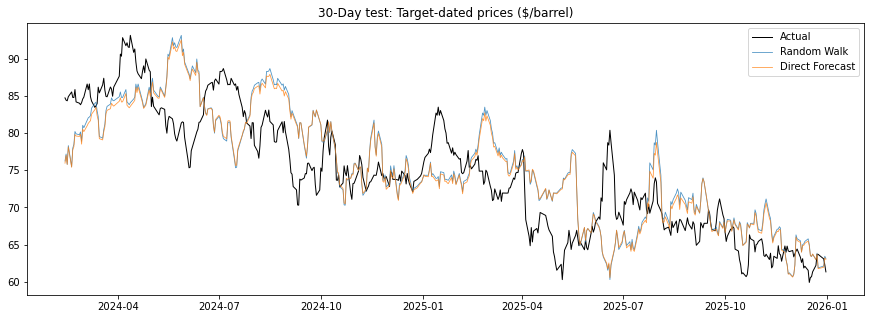

In [15]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(val_results["Random Walk"]["target_date"]), np.array(val_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Forecast"]:
    r = val_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("30-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Test ====

In [16]:
test_args = dict(horizon=30, start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30")

test_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **test_args),
    "Direct Lag_1 Lag_30": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=30, lookback=3000, **test_args),
    "Direct Lag_5 Lag_30": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=30, lookback=3000, **test_args),
    "Mean Revert": walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **test_args),
    "XGBoost": walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **test_args),
    "Direct Ridge": walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **test_args),
    "Combination": walk_forward(data, forecast_funct=combination_forecast, weights=weights, **test_args)
}

compare_models_staggered(test_results, horizon=30)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,22.030881,26.268815,22.610391,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.00000,128
Historical Mean,22.160942,26.398595,22.748229,0.213836,0.260870,0.116505,0.161074,0.194690,0.392857,0.260355,-1.882875,0.555949,-3.386775,-0.673452,0.620313,0.296875,7.61250,128
AR,22.164488,26.399868,22.752785,0.245283,0.302326,0.126214,0.178082,0.224138,0.464286,0.302326,-1.736935,0.564199,-3.078586,-0.657316,0.571354,0.234375,7.21875,128
Direct Forecast,22.072046,26.519883,22.640305,0.358491,0.509091,0.271845,0.354430,0.278846,0.517857,0.362500,-1.084339,0.687381,-1.577494,-0.618127,0.789062,0.421875,6.56250,128
Direct Lag_1 Lag_30,22.078525,26.525176,22.635357,0.427673,0.593750,0.368932,0.455090,0.315789,0.535714,0.397351,-0.735631,0.612009,-1.201992,-0.520650,0.669271,0.476562,6.82500,128
Direct Lag_5 Lag_30,21.719428,26.544603,22.244005,0.496855,0.676923,0.427184,0.523810,0.372340,0.625000,0.466667,-0.524196,0.395320,-1.326005,-0.368591,0.417188,0.382812,7.87500,128
Mean Revert,21.903335,26.652639,22.489172,0.415094,0.589286,0.320388,0.415094,0.320388,0.589286,0.415094,-0.748393,0.598137,-1.251206,-0.536535,0.707292,0.398438,7.48125,128
XGBoost,23.204611,27.736333,24.137076,0.509434,0.591241,0.786408,0.675000,0.000000,0.000000,0.000000,0.542848,0.723661,0.750141,-0.504160,0.901042,1.000000,2.88750,128
Direct Ridge,22.138857,26.389713,22.714777,0.396226,0.555556,0.339806,0.421687,0.291667,0.500000,0.368421,-1.113838,0.513780,-2.167927,-0.529918,0.529687,0.367188,9.58125,128


In [17]:
for loss in ["ae", "se"]:
    print(f"\nDM test vs Random Walk, loss = {loss}")
    print(dm_table(test_results, benchmark="Random Walk", horizon=30, loss=loss).round(4))


DM test vs Random Walk, loss = ae
                     DM_stat  p_value      n
Historical Mean       1.6542   0.1001  159.0
AR                    1.6115   0.1091  159.0
Direct Forecast       0.8327   0.4063  159.0
Direct Lag_1 Lag_30   0.8802   0.3801  159.0
Direct Lag_5 Lag_30   0.9946   0.3215  159.0
Mean Revert           0.4241   0.6720  159.0
XGBoost               0.6233   0.5340  159.0
Direct Ridge          1.3343   0.1840  159.0
Combination           1.2761   0.2038  159.0

DM test vs Random Walk, loss = se
                     DM_stat  p_value      n
Historical Mean       1.6542   0.1001  159.0
AR                    1.6115   0.1091  159.0
Direct Forecast       0.8327   0.4063  159.0
Direct Lag_1 Lag_30   0.8802   0.3801  159.0
Direct Lag_5 Lag_30   0.9946   0.3215  159.0
Mean Revert           0.4241   0.6720  159.0
XGBoost               0.6233   0.5340  159.0
Direct Ridge          1.3343   0.1840  159.0
Combination           1.2761   0.2038  159.0


In [18]:
keys = {name: test_results[name] for name in
         ["Random Walk", "Historical Mean", "AR", "Direct Forecast", "Direct Lag_1 Lag_30", "Direct Ridge", "XGBoost"]}
volatility = garch_volatility(df_rr, col="log_return")
compare_vol_regimes(keys, volatility)[["MAPE_low_vol", "MAPE_high_vol"]].round(4)

,MAPE_low_vol,MAPE_high_vol
Random Walk,22.1582,23.0569
Historical Mean,22.4024,23.0897
AR,22.4061,23.0951
Direct Forecast,22.2658,23.0102
Direct Lag_1 Lag_30,22.0879,23.1760
Direct Ridge,22.2611,23.1628
XGBoost,20.8485,27.3845


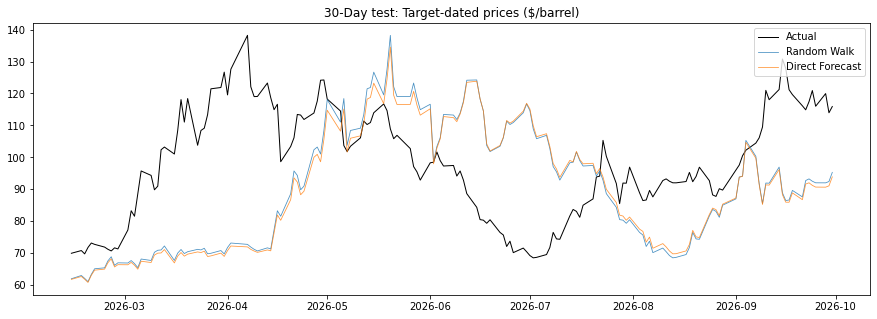

In [19]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(test_results["Random Walk"]["target_date"]), np.array(test_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Forecast"]:
    r = test_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("30-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Final 30-day forecast =====
origin = 2026-09-30

In [20]:
from src.final_forecast import direct_report, final_forecast, make_model

In [22]:
# Model with a GARCH interval
# Switching models: "direct", "direct_lags", "xgboost", "combination" or "random_walk"

# df_rr["log_return"] = np.log(df_rr["brent_spot"]).diff()
# df_rr = df_rr.dropna()
# final = final_forecast(df_rr, partial(direct_ridge_forecast, lookback=3000), horizon=30, origin_date="2026-09-30")
final = final_forecast(data, make_model("direct", 30, lookback=3000), horizon=30, origin_date="2026-09-30")

Origin 2026-09-30   price = 115.91
Horizon: 30 trading days  (target ~ 2026-11-11)
Predicted 30-day log return = -0.0061
Point forecast : 115.20   (random walk: 115.91)
95% prediction interval (garch): 81.53 to 162.77

19 trading days elapsed. Latest 2026-10-27: 123.10 (realised log return +0.0602)
